**Célula 0** — Carrega a imagem com OpenCV, mostra ela e pega as dimensões: `n=x` (linhas), `m=x` (colunas), `c=3` (canais de cor, BGR).

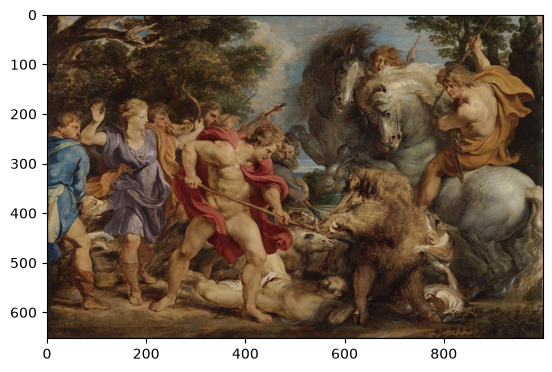

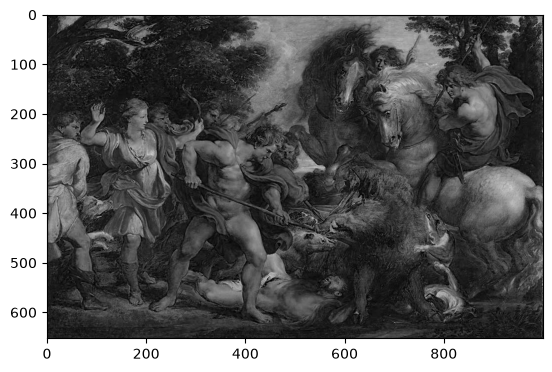

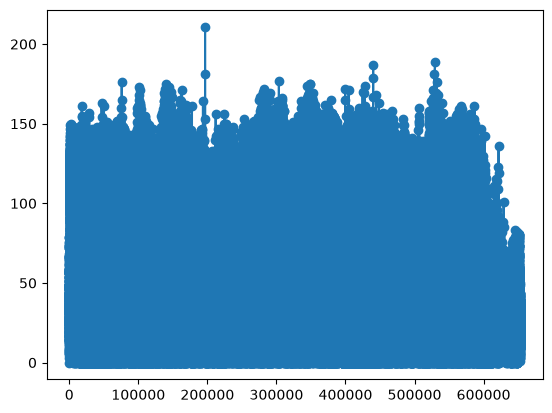

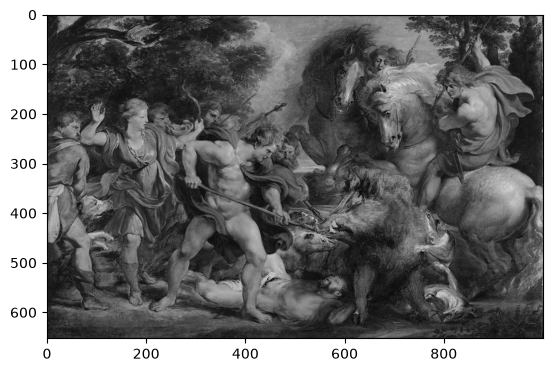

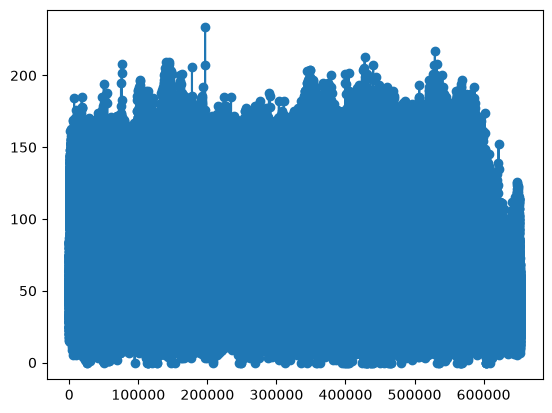

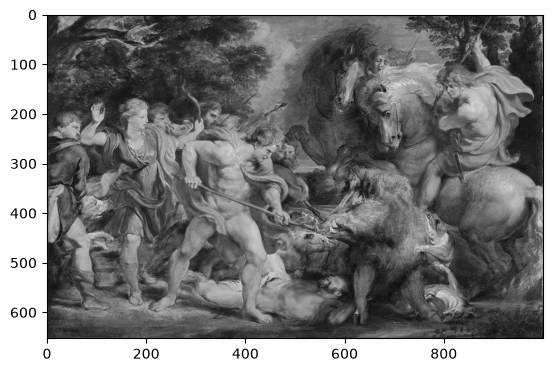

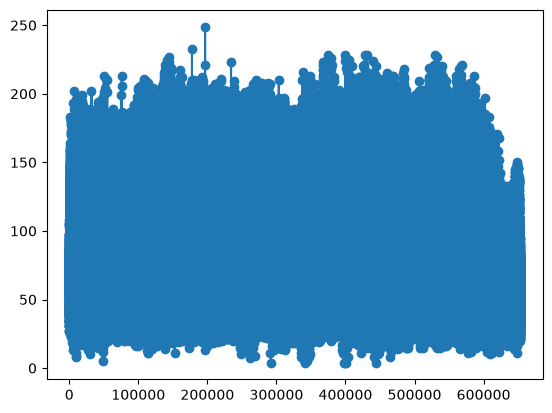

In [1]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

img = cv2.imread('../images/Rubens.jpg')
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

# Quantidade de clusters
K = 2

# Linhas, colunas e cores da imagem
n, m, c = img.shape

PLANO = []
FAIXA = []

# Separa a imagem nos planos de cor (B, G, R) e mostra cada um em escala cinza
for cor in range(c):
    PLANO.append(img[:, :, cor])
    plt.figure()
    plt.imshow(PLANO[-1], cmap='gray')
    plt.show()
    
    # Usando flatten() achata cada plano de cor em um vetor 1D e plota
    # os valores de intensidade de cada pixel em sequencia
    FAIXA.append(PLANO[cor].flatten())
    plt.figure()
    plt.plot(FAIXA[-1])
    plt.scatter(np.arange(len(FAIXA[-1])), FAIXA[-1])
    plt.show()
    

In [2]:
import time

inicio_clusterizacao = time.perf_counter()
MAX_ITER = 50
K = 2

pixels = img.reshape(-1, 3)
npx = len(pixels)

# BLOCO I - inicialização dos centróides
centroid = []

for k in range(K):
    px = np.random.randint(0, npx)
    centroid.append(pixels[px])

centroid = np.array(centroid)

iter = 0

while True:

    # Limpa os clusters para a nova iteração
    CLUSTER = [[] for _ in range(K)]

    # BLOCO A - classificação dos pixels
    for px in range(npx):
        v = np.array([FAIXA[0][px], FAIXA[1][px], FAIXA[2][px]])
        d = []

        for k in range(K):
            d.append(np.linalg.norm(v - centroid[k]))

        cluster = int(np.argmin(d))
        CLUSTER[cluster].append(px)

    # BLOCO C - cálculo dos novos centróides
    NOVO_CENTRIDE = []

    for k in range(K):

        L = len(CLUSTER[k])

        if L == 0:
            NOVO_CENTRIDE.append(centroid[k])
            continue

        S = np.zeros(3)

        for px in CLUSTER[k]:
            S += [ FAIXA[0][px], FAIXA[1][px], FAIXA[2][px]]
            
        NOVO_CENTRIDE.append([ int(S[0] / L), int(S[1] / L), int(S[2] / L)])
        
    NOVO_CENTRIDE = np.array(NOVO_CENTRIDE)

    # BLOCO V - Verifica convergência
    
    conv = np.array_equal(centroid, NOVO_CENTRIDE)

    if conv:
        print(f"Convergiu em {iter} iterações")
        break

    centroid = NOVO_CENTRIDE
    iter += 1

    if iter >= MAX_ITER:
        print(f"Não convergiu em {MAX_ITER} iterações")
        break
    

fim_clusterizacao = time.perf_counter()
tempo_clusterizacao = fim_clusterizacao - inicio_clusterizacao



Convergiu em 2 iterações


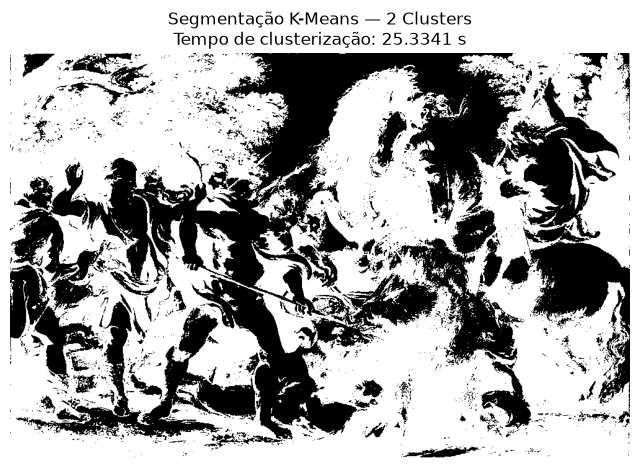

In [3]:
# ============================================================
# GERA IMAGEM BINÁRIA A PARTIR DOS CLUSTERS
# ============================================================

img_cluster = np.zeros_like(pixels)

# Cluster 0 -> preto
for px in CLUSTER[0]:
    img_cluster[px] = [0, 0, 0]

# Cluster 1 -> branco
for px in CLUSTER[1]:
    img_cluster[px] = [255, 255, 255]

# Volta para o formato original da imagem
img_cluster = img_cluster.reshape(img.shape)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8, 8))

plt.imshow(img_cluster)
plt.title(
    f"Segmentação K-Means — {K} Clusters\n"
    f"Tempo de clusterização: {tempo_clusterizacao:.4f} s"
)
plt.axis("off")

plt.savefig(
    "image_result_k2.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

In [4]:
H, W = img.shape
for k in range(K):
    L += len(CLUSTER[k])
print(f'L={L} vs {H*W}')

ValueError: too many values to unpack (expected 2)

In [ ]:
color = [[255, 0, 0], [0, 255, 0], [0, 0, 255]]
segmented = np.empty((H, W, 3), dtype=np.int8)

for k in range(K):
    for px in CLUSTER[k]:
        i = px // W
        j = px % W
        segmented[i, j] = color[k]
plt.imshow(segmented)
plt.show()